This notebook accompanies [06-validation-and-uncertainty](https://xing-phys.github.io/ai-for-physics/06-validation-and-uncertainty.html). Run cells from top to bottom. The web chapter provides typeset citations and numbered cross-references. Teaching code: MIT; text and figures: CC BY 4.0. All data are generated locally.


# What makes a learned result trustworthy? 

## Accuracy is a statement about a question

Imagine a force model with an excellent average error that occasionally produces an enormous attractive force. In a long simulation, the rare failure may dominate the trajectory. Imagine a phase classifier that recognizes temperature from an image border. Its held-out accuracy can be excellent if the same border artifact occurs in the test set. Scientific validation must test the intended use, not merely a convenient score.

This chapter uses the probability and fitting tools developed in Chapters 2–5. Its goals are to design informative tests, separate uncertainty sources, derive elementary calibration procedures, and understand why extrapolation and conserved quantities require special care. These principles will be used throughout the research bridges.

## A hierarchy of numerical questions

Begin with **verification**: does the implementation solve the equations it claims to implement? Compare analytic limits, small exact systems, gradients, and conserved quantities. Then ask **validation**: are those equations and approximations adequate for the physical system and task? Agreement with a discretized model is not evidence that the model describes an experiment outside its assumptions.

A useful test hierarchy is:

1. Check units, shapes, signs, normalization, and exact symmetries.
2. Check small systems or analytically solvable limits.
3. Vary sample size, resolution, model capacity, and optimization effort.
4. Compare independent algorithms with different dominant errors.
5. Test new regimes, preparation conditions, and independent experiments.

Each level answers a different question. Two implementations can agree because they share the same approximation. A symmetry test can pass while the energy is wrong. A small exact calculation can validate an estimator but say little about mixing at a much larger system size.

## Choosing errors that match the physics

The mean absolute error is $N^{-1}\sum_i|\widehat y_i-y_i|$; RMSE is $[N^{-1}\sum_i(\widehat y_i-y_i)^2]^{1/2}$. RMSE penalizes large deviations more strongly. Relative error $|\widehat y-y|/|y|$ is unstable near zero. A normalized field error $\|\widehat u-u\|_2/\|u\|_2$ needs a specified quadrature weight and a nonzero denominator.

An extensive energy can scale as $N$, making energy per particle a useful comparison across sizes. But a small energy-density error can still change a tiny energy difference between competing phases. Report the observable relevant to the conclusion, including its uncertainty. A neural wavefunction with low energy is not automatically accurate for long-range correlation or entanglement; Chapter 7 derives the assumptions needed to relate energy error to state fidelity.

For a chaotic trajectory, a pointwise long-time position error may grow rapidly even for an accurate model. Statistical observables, invariant measures, transport coefficients, and finite-time predictability may be the meaningful quantities instead. Conversely, matching long-time statistics alone is insufficient when the task requires an accurate short-time control signal.

## Independent tests require an independent unit

If a dataset contains 100 trajectories with 1000 time points each, there are not necessarily 100,000 independent examples. A random split over time points may put almost identical neighboring states into training and test sets. Split by trajectory when predicting new trajectories; by material family when predicting new compositions; by experimental run when detector drift matters. The split should reproduce the separation between information available during training and information available in deployment.

For cross-validation, partition independent units into $K$ folds and rotate which fold serves as validation. It estimates variability under repeated partitions, not all possible distribution changes. Hyperparameter choices still need a final independent assessment. Confidence intervals based on the number of correlated rows exaggerate precision; use independent runs or an appropriate block analysis.

### Learning curves and controlled interventions

Plot error versus training set size at a fixed training procedure. A plateau can mean model bias, label noise, incomplete optimization, or insufficiently diverse data. Distinguish these by changing one factor at a time. Increasing network size while simultaneously changing the optimizer and dataset does not isolate which change helped.

Test **in-distribution interpolation** separately from **distribution shift**. Shift can concern input frequency, noise, boundary conditions, system size, composition, or the underlying law. Training at several temperatures and predicting an intermediate temperature differs from training only at weak coupling and predicting a strongly correlated regime. State the domain explicitly.

## Aleatoric and epistemic uncertainty

**Aleatoric uncertainty** describes randomness in observations given the modeled state, such as shot noise. **Epistemic uncertainty** describes imperfect knowledge of parameters or the model. The distinction depends on the modeling level: unresolved environmental fluctuations may be treated as noise in one model and as hidden state variables in another.

For a Bayesian predictor with parameters $\theta$ and data $D$, the predictive distribution is $p(y_*\mid x_*,D)=\int p(y_*\mid x_*,\theta)p(\theta\mid D)d\theta$. Applying the law of total variance gives

$$
\operatorname{Var}(y_*\mid D)=
\mathbb E_{\theta\mid D}[\operatorname{Var}(y_*\mid\theta)]
+\operatorname{Var}_{\theta\mid D}[\mathbb E(y_*\mid\theta)].
$$ 

To derive it, write $y_*-\mathbb E y_*=(y_*-\mathbb E[y_*\mid\theta])+(\mathbb E[y_*\mid\theta]-\mathbb E y_*)$. On averaging, the cross term vanishes because its first factor has conditional mean zero. The first contribution is modeled observation noise; the second is parameter uncertainty. Uncertainty from choosing a wrong model family can be missing from both.

An ensemble trains several models using different initializations, data resamples, or architectures. Their disagreement is a useful diagnostic but is not automatically a calibrated posterior. All members can share a systematic bias and confidently agree on the wrong answer. Bootstrap resampling estimates variability under an empirical data model; correlated trajectories require resampling independent blocks rather than individual frames.

## Proper probability scores and calibration

A probabilistic classifier is calibrated if cases assigned probability $q$ have outcome frequency $q$ under the evaluated distribution. Calibration is distinct from classification accuracy. A constant predictor equal to the class prevalence can be calibrated while providing little discrimination.

The Bernoulli log loss is a proper score. If the true probability is $p$, its expected loss is $-p\log q-(1-p)\log(1-q)$. Differentiate to obtain $(q-p)/[q(1-q)]$, which vanishes at $q=p$. The excess expected loss is exactly $D_{\mathrm{KL}}(\operatorname{Bern}(p)\|\operatorname{Bern}(q))$. Therefore truthful probabilities minimize expected log loss within the stated data distribution.

For continuous Gaussian predictions with mean $\mu$ and standard deviation $s>0$, negative log likelihood includes both a residual and a normalization:

$$
\ell(y;\mu,s)=\frac{(y-\mu)^2}{2s^2}+\log s+\frac12\log(2\pi).
$$

Keeping only the residual term would let the model improve the score by taking $s\to\infty$. The log term penalizes unnecessarily broad predictions. If the true noise is heavy tailed, a Gaussian likelihood can still be misspecified; assess coverage and tail behavior.

A reliability diagram bins predicted probabilities and compares them with observed frequencies. Small bins have sampling uncertainty; a smooth-looking curve alone does not establish calibration. Evaluate calibration on data that were not used to tune the recalibration map.

## Split conformal intervals, derived from ranks

Conformal prediction can construct prediction sets with a finite-sample marginal coverage guarantee under exchangeability [@f-conformal]. Here exchangeability means that permuting the calibration examples and the future example does not change their joint distribution. Independent identically distributed samples satisfy it; a drifting experiment or a correlated sequence generally does not.

First train a predictor $\widehat f$ on a separate training set. On $n$ calibration examples compute residual scores $r_i=|y_i-\widehat f(x_i)|$. For desired error probability $\alpha$, let $k=\lceil(n+1)(1-\alpha)\rceil$ and take $q$ as the $k$th smallest score. If $k=n+1$, use $q=+\infty$. Predict the interval

$$
C(x_*)=[\widehat f(x_*)-q,\widehat f(x_*)+q].
$$ 

Why does it work? Conditional on the trained predictor, the $n+1$ residual scores are exchangeable. With no ties, the new score's rank is uniform among $1,\ldots,n+1$. It exceeds the $k$th calibration score with probability at most $(n+1-k)/(n+1)\leq\alpha$. Ties make the stated nonrandomized construction conservative. Thus $P\{y_*\in C(x_*)\}\geq1-\alpha$ when the assumptions hold.

The guarantee is **marginal**, averaged over random calibration data and new inputs. It does not promise 90% coverage at every position, for every material, or conditional on a particular calibration set. A single interval width can be inefficient for spatially varying noise. More elaborate scores can adapt widths, but they retain assumptions that must be checked.

One calibration set: half-width 0.391, empirical coverage 0.884


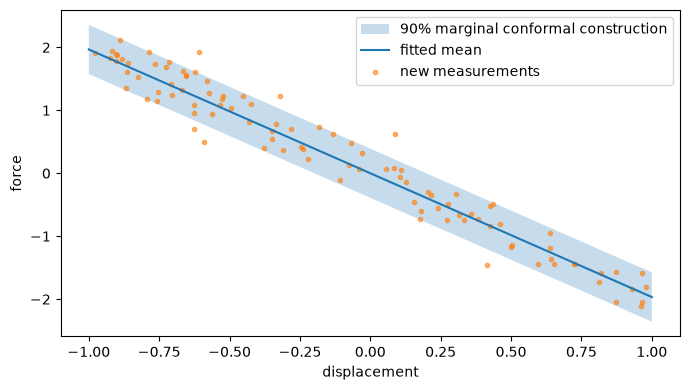

In [1]:
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(606)
def experiment(n, low=-1.0, high=1.0):
    x = rng.uniform(low, high, size=n)
    y = -2*x + rng.normal(0, .25, size=n)
    return x, y
xt, yt = experiment(100)
khat = -np.dot(xt, yt)/np.dot(xt, xt)
xc, yc = experiment(199)
scores = np.abs(yc + khat*xc)
alpha = .1
rank = int(np.ceil((scores.size+1)*(1-alpha)))
q = np.sort(scores)[rank-1]
xnew, ynew = experiment(20_000)
coverage = np.mean(np.abs(ynew+khat*xnew) <= q)
assert np.isfinite(q) and q > 0
# Coverage of one realized calibration set need not exceed the target.
print(f'One calibration set: half-width {q:.3f}, empirical coverage {coverage:.3f}')
grid = np.linspace(-1, 1, 200)
plt.figure(figsize=(7, 4))
plt.fill_between(grid, -khat*grid-q, -khat*grid+q, alpha=.25,
                 label='90% marginal conformal construction')
plt.plot(grid, -khat*grid, label='fitted mean')
plt.scatter(xnew[:100], ynew[:100], s=9, alpha=.6, label='new measurements')
plt.xlabel('displacement'); plt.ylabel('force')
plt.legend(); plt.tight_layout(); plt.show()

The code deliberately avoids asserting that one calibration set achieves at least 90% empirical coverage. That would test a stronger property than the theorem provides. A reproducible test should match the mathematical claim.

## Physical checks beyond held-out loss

For a probability model, test nonnegativity, normalization, support, and observables sensitive to rare configurations. For a quantum state, test energy, variance with correct support conditions, symmetries, and correlations against exact diagonalization where available. For a learned force field, test energy–force consistency, translations, rotations, permutations, and dynamical stability. For a field solver, check boundary conditions, grid refinement, conserved integrals, spectra, and behavior outside its training resolution.

Conservation can be imposed architecturally or approximately through a loss. A small conservation penalty does not imply exact conservation. An exactly conservative representation can still have a large modeling error. Differentiate these statements in reports. If numerical time integration introduces drift, distinguish it from a nonconservative learned vector field by reducing the time step.

A powerful check is an independent limiting case. A weakly coupled lattice should recover known perturbative behavior where the expansion is controlled. A continuum model should have an appropriate discretization limit. A learned experiment policy should be compared against a simple fixed schedule and an information-based design at the same budget. Such checks connect numerical accuracy to physical meaning.

## Reporting a scientific result

State the physical question, model assumptions, data-generation procedure, independent unit of splitting, baseline, observable, error bars, and computational budget. Record random seeds and software versions; report repeated-run variability when optimization is stochastic. Give enough information to reconstruct a failed run as well as the best one.

Separate the result from its interpretation. “The network reduces energy error on these clusters” is an observation. “This phase is stable in the thermodynamic limit” requires size scaling and additional physical analysis. “This architecture overcomes the sign problem generally” would require much stronger evidence than success on selected Hamiltonians. The same discipline applies to claims of autonomous discovery: proposal, verification, and novelty are different questions.

## Exercises and worked solutions

1. A 20-particle model has energy error $0.01$ per particle. Competing phases differ by $0.002$ per particle. Can the model establish their ordering from that metric alone?
2. Derive @eq-valid-total-variance for a mixture of two equally weighted predictive Gaussians with means $\pm a$ and common variance $s^2$.
3. For $n=99$ calibration scores and $\alpha=0.1$, which ordered score defines the split conformal threshold?
4. Two force models conserve energy exactly under exact integration. Does that imply equal trajectories or accurate equilibrium distributions?

**Solutions.** (1) No. The typical error exceeds the relevant difference; correlated errors might cancel, but that cancellation needs direct validation on phase differences. (2) The conditional variance term is $s^2$; the variance of the means is $a^2$, giving total variance $s^2+a^2$. (3) $k=\lceil100\cdot0.9\rceil=90$. (4) No. They can conserve different, incorrect Hamiltonians. Conservation tests structure, while trajectory and distribution accuracy test the learned physical content.

With the statistical and computational foundations in place, the next chapter develops the quantum many-body problem and the role of compact learned wavefunctions.